# NewsScope - 05. Topic Modelling

## Phase F: Unsupervised Topic Discovery and Thematic Analysis

This notebook implements and evaluates latent topic discovery on the **AG News** dataset:
1. **Classical Topic Models (Stage B)**:
   - **Latent Dirichlet Allocation (LDA)**: Generative probabilistic model based on document-topic and topic-word Dirichlet distributions.
   - **Non-negative Matrix Factorization (NMF)**: Linear algebraic matrix factorisation ($V \approx W \times H$) decomposing TF-IDF term weights.
   - **Latent Semantic Analysis (LSA)**: Dimensionality reduction via Truncated Singular Value Decomposition (SVD).
2. **Neural Topic Modelling (Stage C - Pending Dependency Setup)**:
   - **BERTopic**: SentenceTransformer embeddings (`all-MiniLM-L6-v2`) + UMAP dimensionality reduction + HDBSCAN density clustering + c-TF-IDF keyword extraction.
3. **Evaluation & Thematic Validation (Stage D & E)**:
   - Topic coherence ($C_v$ and $C_{\text{NPMI}}$) and topic diversity.
   - Visualisation of top words, topic-document distributions, and post-hoc category alignment against AG News classes.

## Stage A: Setup & Data Sampling

We configure project directories, import core libraries, and draw a reproducible random sample of **3,000 documents** from `data/processed/train_processed.csv`.

### Unsupervised Integrity
- Ground-truth category labels (`label`, `category`) are strictly isolated upon data loading and never passed to vectorizers or topic models.
- The sample is drawn independently of category labels using fixed `random_state=42`.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

# Set reproducible seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Directory paths
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed_dir = project_root / "data" / "processed"
results_dir = project_root / "results" / "topic_modelling"
results_dir.mkdir(parents=True, exist_ok=True)

train_csv_path = processed_dir / "train_processed.csv"
assert train_csv_path.exists(), f"Processed data not found at: {train_csv_path}"

print("Setup completed successfully.")
print(f"  Scikit-Learn: {sklearn.__version__}")
print(f"  Pandas:       {pd.__version__}")
print(f"  NumPy:        {np.__version__}")
print(f"  Results dir:  {results_dir}")

Setup completed successfully.
  Scikit-Learn: 1.9.1
  Pandas:       3.1.1
  NumPy:        2.5.4
  Results dir:  c:\Users\Acer\Downloads\NewsScope\results\topic_modelling


### Load Processed Dataset & Extract Random Sample

We load `train_processed.csv`, extract a sample of 3,000 documents, and check for missing or empty text records.

In [2]:
# Load training dataset
full_df = pd.read_csv(train_csv_path)
print(f"Loaded full dataset: {len(full_df):,} articles.")

# Reproducible random sample of 3,000 documents (selected independently of labels)
sample_df = full_df.sample(n=3000, random_state=RANDOM_STATE).reset_index(drop=True)

# Extract document texts for topic modelling (unsupervised input)
documents = sample_df["clean_text"].tolist()

# Isolate category labels strictly for post-hoc evaluation
true_labels = sample_df["label"].to_numpy()
true_categories = sample_df["category"].to_numpy()
target_names = ["World", "Sports", "Business", "Sci/Tech"]

# Verification checks
print("\n=== Stage A Verification ===")
print(f"Sample size:               {len(documents):,} documents")
print(f"Null texts:                {sample_df['clean_text'].isna().sum()}")
print(f"Empty string texts:        {(sample_df['clean_text'].str.strip() == '').sum()}")
print("\nDistribution across categories in sample:")
display(sample_df["category"].value_counts().rename_axis("Category").reset_index(name="Count"))

print("\nPreview of sampled documents:")
display(sample_df[["category", "clean_text"]].head(4))

Loaded full dataset: 120,000 articles.

=== Stage A Verification ===
Sample size:               3,000 documents
Null texts:                0
Empty string texts:        0

Distribution across categories in sample:


,Category,Count
0,Sports,794
1,Sci/Tech,757
2,World,736
3,Business,713



Preview of sampled documents:


,category,clean_text
0,Business,bbc set major shake claim newspaper london bri...
1,Business,marsh averts cash crunch embattled insurance b...
2,Sports,jeter yankee look take control ap ap derek jet...
3,Sci/Tech,flying sun safety genesis capsule come back ea...


## Stage B: Classical Topic Modelling (LDA, NMF & LSA)

In this stage, we implement three classical topic modelling algorithms with $K = 4$ topics to compare against the four known thematic areas of AG News:
1. **Latent Dirichlet Allocation (LDA)**: A generative Bayesian model assuming each document is a mixture of latent topics, and each topic is a mixture of words (Dirichlet priors). Operates on discrete word count matrices (`CountVectorizer`).
2. **Non-negative Matrix Factorization (NMF)**: Decomposes the term-document matrix $V \approx W \times H$ under non-negativity constraints ($W, H \ge 0$). Matrix $W$ represents document-topic memberships, and matrix $H$ represents topic-word weights. Operates on TF-IDF term weights.
3. **Latent Semantic Analysis (LSA / TruncatedSVD)**: Decomposes the term-document matrix using Singular Value Decomposition ($V \approx U \Sigma V^T$) to uncover an orthogonal semantic vector space.

### Document Vectorization for Classical Models
We construct:
- **Count Matrix** (`CountVectorizer` with `min_df=3, max_df=0.95`) for LDA.
- **TF-IDF Matrix** (`TfidfVectorizer` with `min_df=3, max_df=0.95, norm='l2'`) for NMF and LSA.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Word counts for LDA
count_vec = CountVectorizer(min_df=3, max_df=0.95)
X_counts = count_vec.fit_transform(documents)
count_feature_names = count_vec.get_feature_names_out()

# 2. TF-IDF for NMF and LSA
tfidf_vec = TfidfVectorizer(min_df=3, max_df=0.95, norm="l2")
X_tfidf = tfidf_vec.fit_transform(documents)
tfidf_feature_names = tfidf_vec.get_feature_names_out()

print("=== Vectorization Summary ===")
print(f"Vocabulary size:               {len(count_feature_names):,} terms")
print(f"Count matrix shape (LDA):       {X_counts.shape}")
print(f"TF-IDF matrix shape (NMF/LSA): {X_tfidf.shape}")

=== Vectorization Summary ===
Vocabulary size:               4,201 terms
Count matrix shape (LDA):       (3000, 4201)
TF-IDF matrix shape (NMF/LSA): (3000, 4201)


### Helper Utilities for Topic Inspection
We define reusable functions to extract top words, format topic tables, and identify the most representative documents for each topic.

In [4]:
# Registry to store classical model results
classical_models = {}
classical_doc_topics = {}
classical_top_words = {}
classical_runtimes = {}

def get_top_topic_words(components, feature_names, top_n=10):
    """Extracts the top N words and their weights for each topic."""
    topics = {}
    for topic_idx, topic in enumerate(components):
        top_indices = topic.argsort()[:-top_n - 1:-1]
        topics[f"Topic {topic_idx + 1}"] = [feature_names[i] for i in top_indices]
    return pd.DataFrame(topics)

def display_representative_docs(doc_topics, documents, categories, model_name, n_docs=2):
    """Finds and displays documents with highest assignment probability for each topic."""
    print(f"\n--- Representative Documents for {model_name} ---")
    for topic_idx in range(doc_topics.shape[1]):
        top_doc_indices = doc_topics[:, topic_idx].argsort()[:-n_docs - 1:-1]
        print(f"\n[Topic {topic_idx + 1} - Top Assigned Documents]")
        for rank, doc_idx in enumerate(top_doc_indices):
            prob = doc_topics[doc_idx, topic_idx]
            cat = categories[doc_idx]
            text_snip = documents[doc_idx][:120]
            print(f"  Doc #{doc_idx} (Weight: {prob:.3f}, True Category: {cat}): {text_snip}...")

### 1. Latent Dirichlet Allocation (LDA)
We fit LDA with $K = 4$ topics using batch variational inference.

In [5]:
from sklearn.decomposition import LatentDirichletAllocation

print("Fitting Latent Dirichlet Allocation (LDA, K=4)...")
t0 = time.time()
lda_model = LatentDirichletAllocation(
    n_components=4,
    random_state=RANDOM_STATE,
    learning_method="batch",
    max_iter=25,
)
lda_doc_topics = lda_model.fit_transform(X_counts)
lda_time = time.time() - t0

classical_models["LDA"] = lda_model
classical_doc_topics["LDA"] = lda_doc_topics
classical_runtimes["LDA"] = lda_time
classical_top_words["LDA"] = get_top_topic_words(lda_model.components_, count_feature_names)

print(f"LDA training completed in {lda_time:.2f}s")
print("\nTop 10 Words per Topic (LDA):")
display(classical_top_words["LDA"])

# Representative documents
display_representative_docs(lda_doc_topics, documents, true_categories, "LDA", n_docs=2)

Fitting Latent Dirichlet Allocation (LDA, K=4)...
LDA training completed in 24.59s

Top 10 Words per Topic (LDA):


,Topic 1,Topic 2,Topic 3,Topic 4
0,new,quot,said,game
1,reuters,president,iraq,ap
2,company,said,official,first
3,said,new,reuters,team
4,inc,bush,force,win
5,price,ap,killed,season
6,oil,say,attack,night
7,stock,talk,ap,last
8,microsoft,election,people,two
9,service,union,two,new



--- Representative Documents for LDA ---

[Topic 1 - Top Assigned Documents]
  Doc #458 (Weight: 0.986, True Category: Business): cable veteran bid adelphia auction new york reuters several cable industry pioneer may bid part bankrupt cable operator ...
  Doc #1404 (Weight: 0.986, True Category: Sci/Tech): siebel creates cheaper smb software version siebel systemshas quietly introduced version crm customer relationship manag...

[Topic 2 - Top Assigned Documents]
  Doc #908 (Weight: 0.984, True Category: World): congress sends bush tax cut bill victory washington legislation extending three popular middle class tax cut rest decade...
  Doc #986 (Weight: 0.983, True Category: World): india pakistan discus joint project kashmir united state new york leader india pakistan yesterday hailed new era often f...

[Topic 3 - Top Assigned Documents]
  Doc #243 (Weight: 0.978, True Category: Sci/Tech): lost vote cautionary tale four year ago voter cast ballot election day state art push button e

### 2. Non-negative Matrix Factorization (NMF)
We fit NMF with $K = 4$ topics using Non-negative Double Singular Value Decomposition (`nndsvd`) initialization.

In [6]:
from sklearn.decomposition import NMF

print("Fitting Non-negative Matrix Factorization (NMF, K=4)...")
t0 = time.time()
nmf_model = NMF(
    n_components=4,
    random_state=RANDOM_STATE,
    init="nndsvd",
    max_iter=300,
)
nmf_doc_topics = nmf_model.fit_transform(X_tfidf)
nmf_time = time.time() - t0

classical_models["NMF"] = nmf_model
classical_doc_topics["NMF"] = nmf_doc_topics
classical_runtimes["NMF"] = nmf_time
classical_top_words["NMF"] = get_top_topic_words(nmf_model.components_, tfidf_feature_names)

print(f"NMF training completed in {nmf_time:.2f}s")
print("\nTop 10 Words per Topic (NMF):")
display(classical_top_words["NMF"])

# Representative documents
display_representative_docs(nmf_doc_topics, documents, true_categories, "NMF", n_docs=2)

Fitting Non-negative Matrix Factorization (NMF, K=4)...
NMF training completed in 0.15s

Top 10 Words per Topic (NMF):


,Topic 1,Topic 2,Topic 3,Topic 4
0,ap,oil,company,quot
1,game,price,microsoft,said
2,first,stock,new,iraq
3,team,reuters,inc,president
4,win,barrel,service,killed
5,season,york,google,official
6,night,crude,software,iraqi
7,league,high,business,election
8,victory,higher,computer,say
9,world,target,corp,afp



--- Representative Documents for NMF ---

[Topic 1 - Top Assigned Documents]
  Doc #223 (Weight: 0.155, True Category: Sports): umass arrest game alcs ap ap university massachusetts police arrested people early wednesday morning red sox tied yankee...
  Doc #2568 (Weight: 0.152, True Category: Sci/Tech): biotechnology shaking pet world ap ap biotechnology revolution shaking pet world...

[Topic 2 - Top Assigned Documents]
  Doc #1158 (Weight: 0.354, True Category: Business): stock future rise oil price ease new york reuters stock pointed slightly higher open monday investor seek bargain oil pr...
  Doc #63 (Weight: 0.330, True Category: Business): oil back winter stock reuters reuters oil price charged back barrel wednesday fresh fall heating oil stock stoked worry ...

[Topic 3 - Top Assigned Documents]
  Doc #757 (Weight: 0.176, True Category: Business): ibm sell computer unit talk china lenovo new york new york united state america international business machine ibm corp ...
  Doc 

### 3. Latent Semantic Analysis (LSA / TruncatedSVD)
We fit TruncatedSVD with $K = 4$ components on the TF-IDF matrix.

In [7]:
from sklearn.decomposition import TruncatedSVD

print("Fitting Latent Semantic Analysis (LSA / TruncatedSVD, K=4)...")
t0 = time.time()
lsa_model = TruncatedSVD(
    n_components=4,
    random_state=RANDOM_STATE,
)
lsa_doc_topics = lsa_model.fit_transform(X_tfidf)
lsa_time = time.time() - t0

classical_models["LSA"] = lsa_model
classical_doc_topics["LSA"] = lsa_doc_topics
classical_runtimes["LSA"] = lsa_time
classical_top_words["LSA"] = get_top_topic_words(lsa_model.components_, tfidf_feature_names)

print(f"LSA training completed in {lsa_time:.2f}s")
print("\nTop 10 Words per Topic (LSA):")
display(classical_top_words["LSA"])

# Representative documents
display_representative_docs(lsa_doc_topics, documents, true_categories, "LSA", n_docs=2)

Fitting Latent Semantic Analysis (LSA / TruncatedSVD, K=4)...
LSA training completed in 0.07s

Top 10 Words per Topic (LSA):


,Topic 1,Topic 2,Topic 3,Topic 4
0,reuters,ap,oil,iraq
1,ap,game,ap,quot
2,new,quot,price,killed
3,said,team,reuters,iraqi
4,year,win,barrel,said
5,oil,two,game,official
6,quot,season,record,baghdad
7,stock,night,stock,troop
8,price,first,crude,oil
9,first,victory,season,president



--- Representative Documents for LSA ---

[Topic 1 - Top Assigned Documents]
  Doc #1158 (Weight: 0.280, True Category: Business): stock future rise oil price ease new york reuters stock pointed slightly higher open monday investor seek bargain oil pr...
  Doc #2580 (Weight: 0.265, True Category: World): stock turn higher oil hit record high new york stock enjoyed late day rally wednesday finish higher despite new record p...

[Topic 2 - Top Assigned Documents]
  Doc #223 (Weight: 0.243, True Category: Sports): umass arrest game alcs ap ap university massachusetts police arrested people early wednesday morning red sox tied yankee...
  Doc #2568 (Weight: 0.220, True Category: Sci/Tech): biotechnology shaking pet world ap ap biotechnology revolution shaking pet world...

[Topic 3 - Top Assigned Documents]
  Doc #63 (Weight: 0.343, True Category: Business): oil back winter stock reuters reuters oil price charged back barrel wednesday fresh fall heating oil stock stoked worry ...
  Doc #1

### Comparison of Classical Topic Models
We compile the top words, runtime, and topic prevalence across all three classical models, and save the extracted topic words to `results/topic_modelling/topic_words.csv`.

In [8]:
# Compile consolidated topic words table
word_dfs = []
for model_name, df_words in classical_top_words.items():
    for col in df_words.columns:
        word_dfs.append({
            "Model": model_name,
            "Topic": col,
            "Top_Words": ", ".join(df_words[col].tolist())
        })

topic_words_df = pd.DataFrame(word_dfs)

# Save topic words to results directory
words_csv_path = results_dir / "topic_words.csv"
topic_words_df.to_csv(words_csv_path, index=False)
print(f"Saved topic words to: {words_csv_path}")

print("\n=== Classical Topic Models Summary ===")
display(topic_words_df)

# Document-topic distribution summary: proportion of documents primarily assigned to each topic
print("\n--- Document Distribution Across Topics ---")
dist_rows = []
for model_name, doc_topics in classical_doc_topics.items():
    dominant_topics = np.argmax(doc_topics, axis=1)
    counts = np.bincount(dominant_topics, minlength=4)
    dist_rows.append({
        "Model": model_name,
        "Runtime_s": round(classical_runtimes[model_name], 2),
        "Topic 1 Docs": counts[0],
        "Topic 2 Docs": counts[1],
        "Topic 3 Docs": counts[2],
        "Topic 4 Docs": counts[3],
    })

dist_df = pd.DataFrame(dist_rows)
display(dist_df)

Saved topic words to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\topic_words.csv

=== Classical Topic Models Summary ===


,Model,Topic,Top_Words
0,LDA,Topic 1,"new, reuters, company, said, inc, price, oil, ..."
1,LDA,Topic 2,"quot, president, said, new, bush, ap, say, tal..."
2,LDA,Topic 3,"said, iraq, official, reuters, force, killed, ..."
3,LDA,Topic 4,"game, ap, first, team, win, season, night, las..."
4,NMF,Topic 1,"ap, game, first, team, win, season, night, lea..."
5,NMF,Topic 2,"oil, price, stock, reuters, barrel, york, crud..."
6,NMF,Topic 3,"company, microsoft, new, inc, service, google,..."
7,NMF,Topic 4,"quot, said, iraq, president, killed, official,..."
8,LSA,Topic 1,"reuters, ap, new, said, year, oil, quot, stock..."
9,LSA,Topic 2,"ap, game, quot, team, win, two, season, night,..."



--- Document Distribution Across Topics ---


,Model,Runtime_s,Topic 1 Docs,Topic 2 Docs,Topic 3 Docs,Topic 4 Docs
0,LDA,24.59,1030,660,494,816
1,NMF,0.15,836,270,999,895
2,LSA,0.07,2477,152,57,314


## Stage C: Neural Topic Modelling (BERTopic)

BERTopic implements a modular, density-based topic modeling architecture combining contextual sentence embeddings with manifold learning and class-based TF-IDF (c-TF-IDF):

1. **Document Embeddings:** Dense semantic vectors generated using a pre-trained SentenceTransformer (`all-MiniLM-L6-v2`, 384 dimensions) capturing semantic context.
2. **Dimensionality Reduction:** UMAP reduces high-dimensional embedding space to 5 components while preserving local cosine neighborhood geometry.
3. **Density Clustering:** HDBSCAN identifies variable-density document clusters without pre-specifying a fixed topic count $K$, isolating noise/transitional texts into an outlier cluster (Topic `-1`).
4. **Topic Representation:** Class-based TF-IDF (c-TF-IDF) extracts the most discriminative unigrams and bigrams per cluster from document word frequencies.

In [9]:
import os
import time
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# Ensure HuggingFace uses local cached model files without network retry delays
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

# 1. Generate or load dense document embeddings
embeddings_path = results_dir / "embeddings_minilm_3000.npy"

if embeddings_path.exists():
    print(f"Loading cached embeddings from: {embeddings_path}")
    embeddings = np.load(embeddings_path)
    embed_time = 0.0
    print(f"Loaded embeddings matrix of shape: {embeddings.shape}")
else:
    print("Generating dense sentence embeddings using all-MiniLM-L6-v2 (384 dimensions)...")
    start_embed = time.time()
    embedding_model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
    embeddings = embedding_model.encode(
        documents,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True
    )
    embed_time = time.time() - start_embed
    np.save(embeddings_path, embeddings)
    print(f"Generated embeddings in {embed_time:.2f}s | Shape: {embeddings.shape}")
    print(f"Saved embeddings cache to: {embeddings_path}")

Loading cached embeddings from: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\embeddings_minilm_3000.npy
Loaded embeddings matrix of shape: (3000, 384)


### BERTopic Modular Pipeline Setup & Fitting
We configure UMAP with cosine distance (`n_neighbors=15, n_components=5, min_dist=0.0`), HDBSCAN with Euclidean distance on the 5D manifold (`min_cluster_size=15, min_samples=10`), and CountVectorizer with English stop words and unigram/bigram extraction. We let HDBSCAN discover natural clusters rather than constraining the model to four broad topics.

In [10]:
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic

# Initialize modular pipeline components
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

hdbscan_model = HDBSCAN(
    min_cluster_size=15,
    min_samples=10,
    metric="euclidean",
    prediction_data=True
)

vectorizer_model = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

topic_model = BERTopic(
    embedding_model=None,  # Pass precomputed embeddings directly
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    top_n_words=10,
    calculate_probabilities=False,
    low_memory=True,
    verbose=False
)

print("Fitting BERTopic on 3,000 documents using precomputed MiniLM embeddings...")
start_fit = time.time()
topics, _ = topic_model.fit_transform(documents, embeddings)
fit_time = time.time() - start_fit
bertopic_total_time = embed_time + fit_time

print(f"BERTopic fitting completed in {fit_time:.2f}s (Total pipeline runtime: {bertopic_total_time:.2f}s)")

Fitting BERTopic on 3,000 documents using precomputed MiniLM embeddings...
BERTopic fitting completed in 33.48s (Total pipeline runtime: 33.48s)


### Topic Discovery, Outlier Analysis & Cluster Inspection
Unlike parametric models (LDA, NMF, LSA) which force every document into one of $K=4$ topics, HDBSCAN separates cohesive semantic clusters from ambiguous or transitional documents, labeling noise as Topic `-1`.

In [11]:
# 1. Topic discovery overview
topic_info = topic_model.get_topic_info()
total_topics_discovered = len(topic_info[topic_info['Topic'] != -1])
outlier_count = int(topic_info.loc[topic_info['Topic'] == -1, 'Count'].values[0]) if -1 in topic_info['Topic'].values else 0
outlier_pct = (outlier_count / len(documents)) * 100

print("=== BERTopic Discovery Summary ===")
print(f"Total documents: {len(documents)}")
print(f"Non-outlier topics discovered: {total_topics_discovered}")
print(f"Outlier documents (Topic -1): {outlier_count} ({outlier_pct:.2f}%)")
print(f"Clustered documents: {len(documents) - outlier_count} ({100 - outlier_pct:.2f}%)")

# Save detailed topic info table
topic_info_path = results_dir / "bertopic_topic_info.csv"
topic_info.to_csv(topic_info_path, index=False)
print(f"Saved BERTopic topic info to: {topic_info_path}")

# Display top 10 non-outlier topics by document volume
print("\n--- Top 10 Discovered Topics by Document Count ---")
display(topic_info[topic_info['Topic'] != -1].head(10)[['Topic', 'Count', 'Name']])

=== BERTopic Discovery Summary ===
Total documents: 3000
Non-outlier topics discovered: 49
Outlier documents (Topic -1): 914 (30.47%)
Clustered documents: 2086 (69.53%)
Saved BERTopic topic info to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\bertopic_topic_info.csv

--- Top 10 Discovered Topics by Document Count ---


,Topic,Count,Name
1,0,201,0_scientist_space_ap_earth
2,1,151,1_sox_yankee_red_red sox
3,2,109,2_league_champion league_champion_manchester
4,3,84,3_athens_gold_olympic_medal
5,4,74,4_bush_kerry_president_tax
6,5,71,5_spam_security_microsoft_mail
7,6,68,6_profit_earnings_quarter_quarterly
8,7,68,7_phone_wireless_mobile_service
9,8,65,8_palestinian_arafat_gaza_israeli
10,9,58,9_oil_oil price_price_barrel


### Top Discriminative Words & Representative Documents
We extract the top 10 c-TF-IDF terms for discovered topics and inspect actual representative news articles to verify semantic coherence across domain themes.

In [12]:
# Extract top 10 c-TF-IDF keywords for all non-outlier topics
bertopic_top_words = {}
for topic_id in topic_info[topic_info['Topic'] != -1]['Topic']:
    top_words = [word for word, score in topic_model.get_topic(topic_id)[:10]]
    bertopic_top_words[f"Topic {topic_id}"] = top_words

# Compile BERTopic words dataframe
bertopic_words_rows = []
for topic_col, words in bertopic_top_words.items():
    bertopic_words_rows.append({
        "Model": "BERTopic",
        "Topic": topic_col,
        "Top_Words": ", ".join(words)
    })
bertopic_words_df = pd.DataFrame(bertopic_words_rows)

# Save BERTopic words to results directory
bertopic_words_path = results_dir / "bertopic_words.csv"
bertopic_words_df.to_csv(bertopic_words_path, index=False)
print(f"Saved BERTopic extracted keywords to: {bertopic_words_path}")

# Update consolidated topic words file by appending BERTopic (preserving classical model words)
all_words_csv_path = results_dir / "topic_words.csv"
if all_words_csv_path.exists():
    existing_words_df = pd.read_csv(all_words_csv_path)
    filtered_df = existing_words_df[existing_words_df['Model'] != 'BERTopic']
    combined_words_df = pd.concat([filtered_df, bertopic_words_df], ignore_index=True)
    combined_words_df.to_csv(all_words_csv_path, index=False)
    print(f"Updated consolidated topic words in: {all_words_csv_path}")

# Display top 5 largest topics with representative articles
print("\n=== Representative Articles for Top 5 Discovered Topics ===")
top_5_topics = topic_info[topic_info['Topic'] != -1].head(5)['Topic'].tolist()
for tid in top_5_topics:
    keywords = ", ".join([w for w, _ in topic_model.get_topic(tid)[:8]])
    count = topic_info.loc[topic_info['Topic'] == tid, 'Count'].values[0]
    rep_docs = topic_model.get_representative_docs(tid)
    print(f"\n[Topic {tid}] (Docs: {count}) Top terms: {keywords}")
    if rep_docs:
        print(f"  Representative Snippet: \"{rep_docs[0][:150]}...\"")

Saved BERTopic extracted keywords to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\bertopic_words.csv
Updated consolidated topic words in: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\topic_words.csv

=== Representative Articles for Top 5 Discovered Topics ===

[Topic 0] (Docs: 201) Top terms: scientist, space, ap, earth, drug, nasa, human, moon
  Representative Snippet: "museum launch name space ap ap new mexico museum space history shipping name star first prize launch space..."

[Topic 1] (Docs: 151) Top terms: sox, yankee, red, red sox, league, series, game, inning
  Representative Snippet: "seeing believing red sox boston pitcher pedro martinez hold championship trophy red sox defeated st louis cardinal game win world series wednesday st..."

[Topic 2] (Docs: 109) Top terms: league, champion league, champion, manchester, arsenal, club, liverpool, chelsea
  Representative Snippet: "chelsea overpower champion porto london england jose mourinho new club chel

## Stage D: Quantitative Evaluation

To rigorously compare the four topic-modelling approaches (**LDA**, **NMF**, **LSA**, and **BERTopic**), we evaluate four complementary quantitative dimensions:

1. **Topic Coherence ($C_v$ and $C_{\text{NPMI}}$):** Evaluates semantic relatedness among top keywords per topic. $C_v$ combines indirect cosine similarity with a sliding window, while $C_{\text{NPMI}}$ measures Normalized Pointwise Mutual Information. Both are evaluated over the exact same tokenized corpus of 3,000 documents using Gensim. For BERTopic, the outlier topic ($-1$) is strictly excluded.
   * *Vocabulary and Bigram Handling:* While classical models extract purely unigram keywords, BERTopic's c-TF-IDF incorporates n-grams up to bigrams, extracting 71 bigram phrases out of 490 total keywords (e.g., `'red sox'`, `'champion league'`, `'gold medal'`). Gensim's `CoherenceModel` filters words against `dictionary.token2id` built from whitespace-separated unigram tokens. Because multi-word phrases contain spaces, all 71 bigrams are treated as out-of-vocabulary and excluded from sliding-window PMI calculations. Consequently, BERTopic's coherence is computed across an average of 8.55 in-vocabulary unigram terms per topic (ranging from 6 to 10 terms), whereas classical models are evaluated on exactly 10 terms per topic.
2. **Topic Diversity:** Measures the proportion of unique terms across all top-10 topic words ($\text{Unique Words} / (K \times 10)$). High diversity indicates that models capture distinct themes without vocabulary redundancy.
3. **Computational Runtime:** Evaluates computational feasibility, distinguishing cached-embedding fitting time from end-to-end cold-start pipeline runtime.
4. **Normalized Mutual Information (NMI):** Compares unsupervised topic assignments against true AG News categories. Category labels were strictly excluded from model training and feature extraction. For BERTopic, NMI is calculated both across all documents (including outliers) and on non-outlier documents.

In [13]:
# 1. Tokenized evaluation corpus & Gensim Dictionary
import gensim
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

tokenized_docs = [doc.split() for doc in documents]
dictionary = Dictionary(tokenized_docs)

# Compile top 10 words for all models
# Classical models: from classical_top_words (unigrams)
# BERTopic: from bertopic_top_words (49 non-outlier topics, includes unigrams & bigrams)
# Note: Gensim CoherenceModel evaluates in-vocabulary tokens against dictionary.token2id,
# calculating sliding-window PMI across the 419 in-vocabulary unigrams for a standardized evaluation space.
eval_topic_words = {}
for model_name, df_w in classical_top_words.items():
    eval_topic_words[model_name] = [df_w[col].tolist() for col in df_w.columns]

eval_topic_words["BERTopic"] = list(bertopic_top_words.values())

# Calculate C_v and C_NPMI Coherence
coherence_records = []
diversity_records = []

for model_name, t_words in eval_topic_words.items():
    cm_cv = CoherenceModel(topics=t_words, texts=tokenized_docs, dictionary=dictionary, coherence='c_v', processes=1)
    cv_score = cm_cv.get_coherence()
    
    cm_npmi = CoherenceModel(topics=t_words, texts=tokenized_docs, dictionary=dictionary, coherence='c_npmi', processes=1)
    npmi_score = cm_npmi.get_coherence()
    
    coherence_records.append({
        "Model": model_name,
        "Topics_Evaluated": len(t_words),
        "C_v": round(cv_score, 4),
        "C_NPMI": round(npmi_score, 4)
    })
    
    # Topic Diversity: Unique Words / Total Words
    flat_words = [w for t in t_words for w in t]
    total_words = len(flat_words)
    unique_words = len(set(flat_words))
    diversity_score = unique_words / total_words if total_words > 0 else 0.0
    
    diversity_records.append({
        "Model": model_name,
        "Topics_Evaluated": len(t_words),
        "Total_Words": total_words,
        "Unique_Words": unique_words,
        "Topic_Diversity": round(diversity_score, 4)
    })

df_coherence = pd.DataFrame(coherence_records)
df_diversity = pd.DataFrame(diversity_records)

# Save coherence and diversity tables
coh_path = results_dir / "topic_coherence.csv"
div_path = results_dir / "topic_diversity.csv"
df_coherence.to_csv(coh_path, index=False)
df_diversity.to_csv(div_path, index=False)
print(f"Saved coherence metrics to: {coh_path}")
print(f"Saved diversity metrics to: {div_path}")

print("\n=== Topic Coherence Summary (Top 10 Words) ===")
display(df_coherence)

print("\n=== Topic Diversity Summary ===")
display(df_diversity)

Saved coherence metrics to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\topic_coherence.csv
Saved diversity metrics to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\topic_diversity.csv

=== Topic Coherence Summary (Top 10 Words) ===


,Model,Topics_Evaluated,C_v,C_NPMI
0,LDA,4,0.5078,0.0290
1,NMF,4,0.6512,0.0790
2,LSA,4,0.4547,-0.0310
3,BERTopic,49,0.6306,0.1155



=== Topic Diversity Summary ===


,Model,Topics_Evaluated,Total_Words,Unique_Words,Topic_Diversity
0,LDA,4,40,32,0.8000
1,NMF,4,40,40,1.0000
2,LSA,4,40,27,0.6750
3,BERTopic,49,490,452,0.9224


### Normalized Mutual Information (NMI) & Category Alignment
We measure how closely unsupervised topic groupings reflect the ground-truth AG News categories (World, Sports, Business, Sci/Tech). 

- For **LDA**, **NMF**, and **LSA**, each document is assigned to its highest-weight topic component across all 3,000 sampled documents.
- For **BERTopic**, HDBSCAN generates fine-grained subtopics and separates ambiguous documents into outlier Topic `-1` (914 documents, 30.47%). We calculate NMI across two scopes:
  1. **All Documents (3,000 docs):** Outlier Topic `-1` is treated as a 50th topic category, providing a direct, full-sample comparison against the classical models.
  2. **Non-Outliers Only (2,086 docs):** Evaluates the cluster assignment quality of confident, non-noise articles. *Important Methodological Note:* Because this excludes 30.47% of ambiguous transition documents, this metric is evaluated on a reduced subset and is **not directly comparable** to the full-sample NMI scores of LDA (0.3822), NMF (0.3858), or LSA (0.2022).

In [14]:
from sklearn.metrics import normalized_mutual_info_score

# Extract document dominant topic assignments
lda_dominant = np.argmax(classical_doc_topics["LDA"], axis=1)
nmf_dominant = np.argmax(classical_doc_topics["NMF"], axis=1)
lsa_dominant = np.argmax(classical_doc_topics["LSA"], axis=1)
bertopic_arr = np.array(topics)

# Calculate NMI scores
nmi_lda = normalized_mutual_info_score(true_labels, lda_dominant)
nmi_nmf = normalized_mutual_info_score(true_labels, nmf_dominant)
nmi_lsa = normalized_mutual_info_score(true_labels, lsa_dominant)
nmi_bert_all = normalized_mutual_info_score(true_labels, bertopic_arr)

# BERTopic excluding outliers
non_outlier_mask = bertopic_arr != -1
nmi_bert_clean = normalized_mutual_info_score(
    true_labels[non_outlier_mask], 
    bertopic_arr[non_outlier_mask]
)

nmi_records = [
    {"Model": "LDA", "Evaluation_Scope": "All Documents (3,000)", "Topics": 4, "NMI": round(nmi_lda, 4)},
    {"Model": "NMF", "Evaluation_Scope": "All Documents (3,000)", "Topics": 4, "NMI": round(nmi_nmf, 4)},
    {"Model": "LSA", "Evaluation_Scope": "All Documents (3,000)", "Topics": 4, "NMI": round(nmi_lsa, 4)},
    {"Model": "BERTopic (All Docs)", "Evaluation_Scope": "All Documents (incl. outliers)", "Topics": total_topics_discovered + 1, "NMI": round(nmi_bert_all, 4)},
    {"Model": "BERTopic (Clean)", "Evaluation_Scope": "Non-Outliers Only (2,086)", "Topics": total_topics_discovered, "NMI": round(nmi_bert_clean, 4)},
]
df_nmi = pd.DataFrame(nmi_records)
nmi_path = results_dir / "topic_nmi_comparison.csv"
df_nmi.to_csv(nmi_path, index=False)
print(f"Saved NMI comparison to: {nmi_path}")
display(df_nmi)

# Consolidated Master Comparison Table
comparison_records = [
    {
        "Model": "LDA",
        "Discovered_Topics": 4,
        "Outlier_Pct": 0.0,
        "Runtime_Fitting_s": round(classical_runtimes["LDA"], 2),
        "Runtime_Total_s": round(classical_runtimes["LDA"], 2),
        "Coherence_Cv": df_coherence.loc[df_coherence['Model'] == 'LDA', 'C_v'].values[0],
        "Coherence_NPMI": df_coherence.loc[df_coherence['Model'] == 'LDA', 'C_NPMI'].values[0],
        "Topic_Diversity": df_diversity.loc[df_diversity['Model'] == 'LDA', 'Topic_Diversity'].values[0],
        "NMI_All_Docs": round(nmi_lda, 4),
        "NMI_Excl_Outliers": np.nan
    },
    {
        "Model": "NMF",
        "Discovered_Topics": 4,
        "Outlier_Pct": 0.0,
        "Runtime_Fitting_s": round(classical_runtimes["NMF"], 2),
        "Runtime_Total_s": round(classical_runtimes["NMF"], 2),
        "Coherence_Cv": df_coherence.loc[df_coherence['Model'] == 'NMF', 'C_v'].values[0],
        "Coherence_NPMI": df_coherence.loc[df_coherence['Model'] == 'NMF', 'C_NPMI'].values[0],
        "Topic_Diversity": df_diversity.loc[df_diversity['Model'] == 'NMF', 'Topic_Diversity'].values[0],
        "NMI_All_Docs": round(nmi_nmf, 4),
        "NMI_Excl_Outliers": np.nan
    },
    {
        "Model": "LSA",
        "Discovered_Topics": 4,
        "Outlier_Pct": 0.0,
        "Runtime_Fitting_s": round(classical_runtimes["LSA"], 2),
        "Runtime_Total_s": round(classical_runtimes["LSA"], 2),
        "Coherence_Cv": df_coherence.loc[df_coherence['Model'] == 'LSA', 'C_v'].values[0],
        "Coherence_NPMI": df_coherence.loc[df_coherence['Model'] == 'LSA', 'C_NPMI'].values[0],
        "Topic_Diversity": df_diversity.loc[df_diversity['Model'] == 'LSA', 'Topic_Diversity'].values[0],
        "NMI_All_Docs": round(nmi_lsa, 4),
        "NMI_Excl_Outliers": np.nan
    },
    {
        "Model": "BERTopic",
        "Discovered_Topics": total_topics_discovered,
        "Outlier_Pct": round(outlier_pct, 2),
        "Runtime_Fitting_s": round(fit_time, 2),
        "Runtime_Total_s": round(bertopic_total_time, 2),
        "Coherence_Cv": df_coherence.loc[df_coherence['Model'] == 'BERTopic', 'C_v'].values[0],
        "Coherence_NPMI": df_coherence.loc[df_coherence['Model'] == 'BERTopic', 'C_NPMI'].values[0],
        "Topic_Diversity": df_diversity.loc[df_diversity['Model'] == 'BERTopic', 'Topic_Diversity'].values[0],
        "NMI_All_Docs": round(nmi_bert_all, 4),
        "NMI_Excl_Outliers": round(nmi_bert_clean, 4)
    }
]
df_comparison = pd.DataFrame(comparison_records)
comp_path = results_dir / "topic_model_comparison.csv"
df_comparison.to_csv(comp_path, index=False)
print(f"\nSaved consolidated model comparison to: {comp_path}")

print("\n=== Consolidated Topic Models Evaluation Table ===")
display(df_comparison)

Saved NMI comparison to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\topic_nmi_comparison.csv


,Model,Evaluation_Scope,Topics,NMI
0,LDA,"All Documents (3,000)",4,0.3822
1,NMF,"All Documents (3,000)",4,0.3858
2,LSA,"All Documents (3,000)",4,0.2022
3,BERTopic (All Docs),All Documents (incl. outliers),50,0.3151
4,BERTopic (Clean),"Non-Outliers Only (2,086)",49,0.4041



Saved consolidated model comparison to: c:\Users\Acer\Downloads\NewsScope\results\topic_modelling\topic_model_comparison.csv

=== Consolidated Topic Models Evaluation Table ===


,Model,Discovered_Topics,Outlier_Pct,Runtime_Fitting_s,Runtime_Total_s,Coherence_Cv,Coherence_NPMI,Topic_Diversity,NMI_All_Docs,NMI_Excl_Outliers
0,LDA,4,0.00,24.59,24.59,0.5078,0.0290,0.8000,0.3822,NaN
1,NMF,4,0.00,0.15,0.15,0.6512,0.0790,1.0000,0.3858,NaN
2,LSA,4,0.00,0.07,0.07,0.4547,-0.0310,0.6750,0.2022,NaN
3,BERTopic,49,30.47,33.48,33.48,0.6306,0.1155,0.9224,0.3151,0.4041


## Stage E: Visualisation and Comparison

We generate academic visualisations comparing model coherence, topic diversity, computational runtimes, topic granularity, document distributions, and alignment against ground-truth AG News categories.

Saved: results\topic_modelling\topic_coherence_comparison.png
Saved: results\topic_modelling\topic_diversity_comparison.png
Saved: results\topic_modelling\topic_runtime_comparison.png


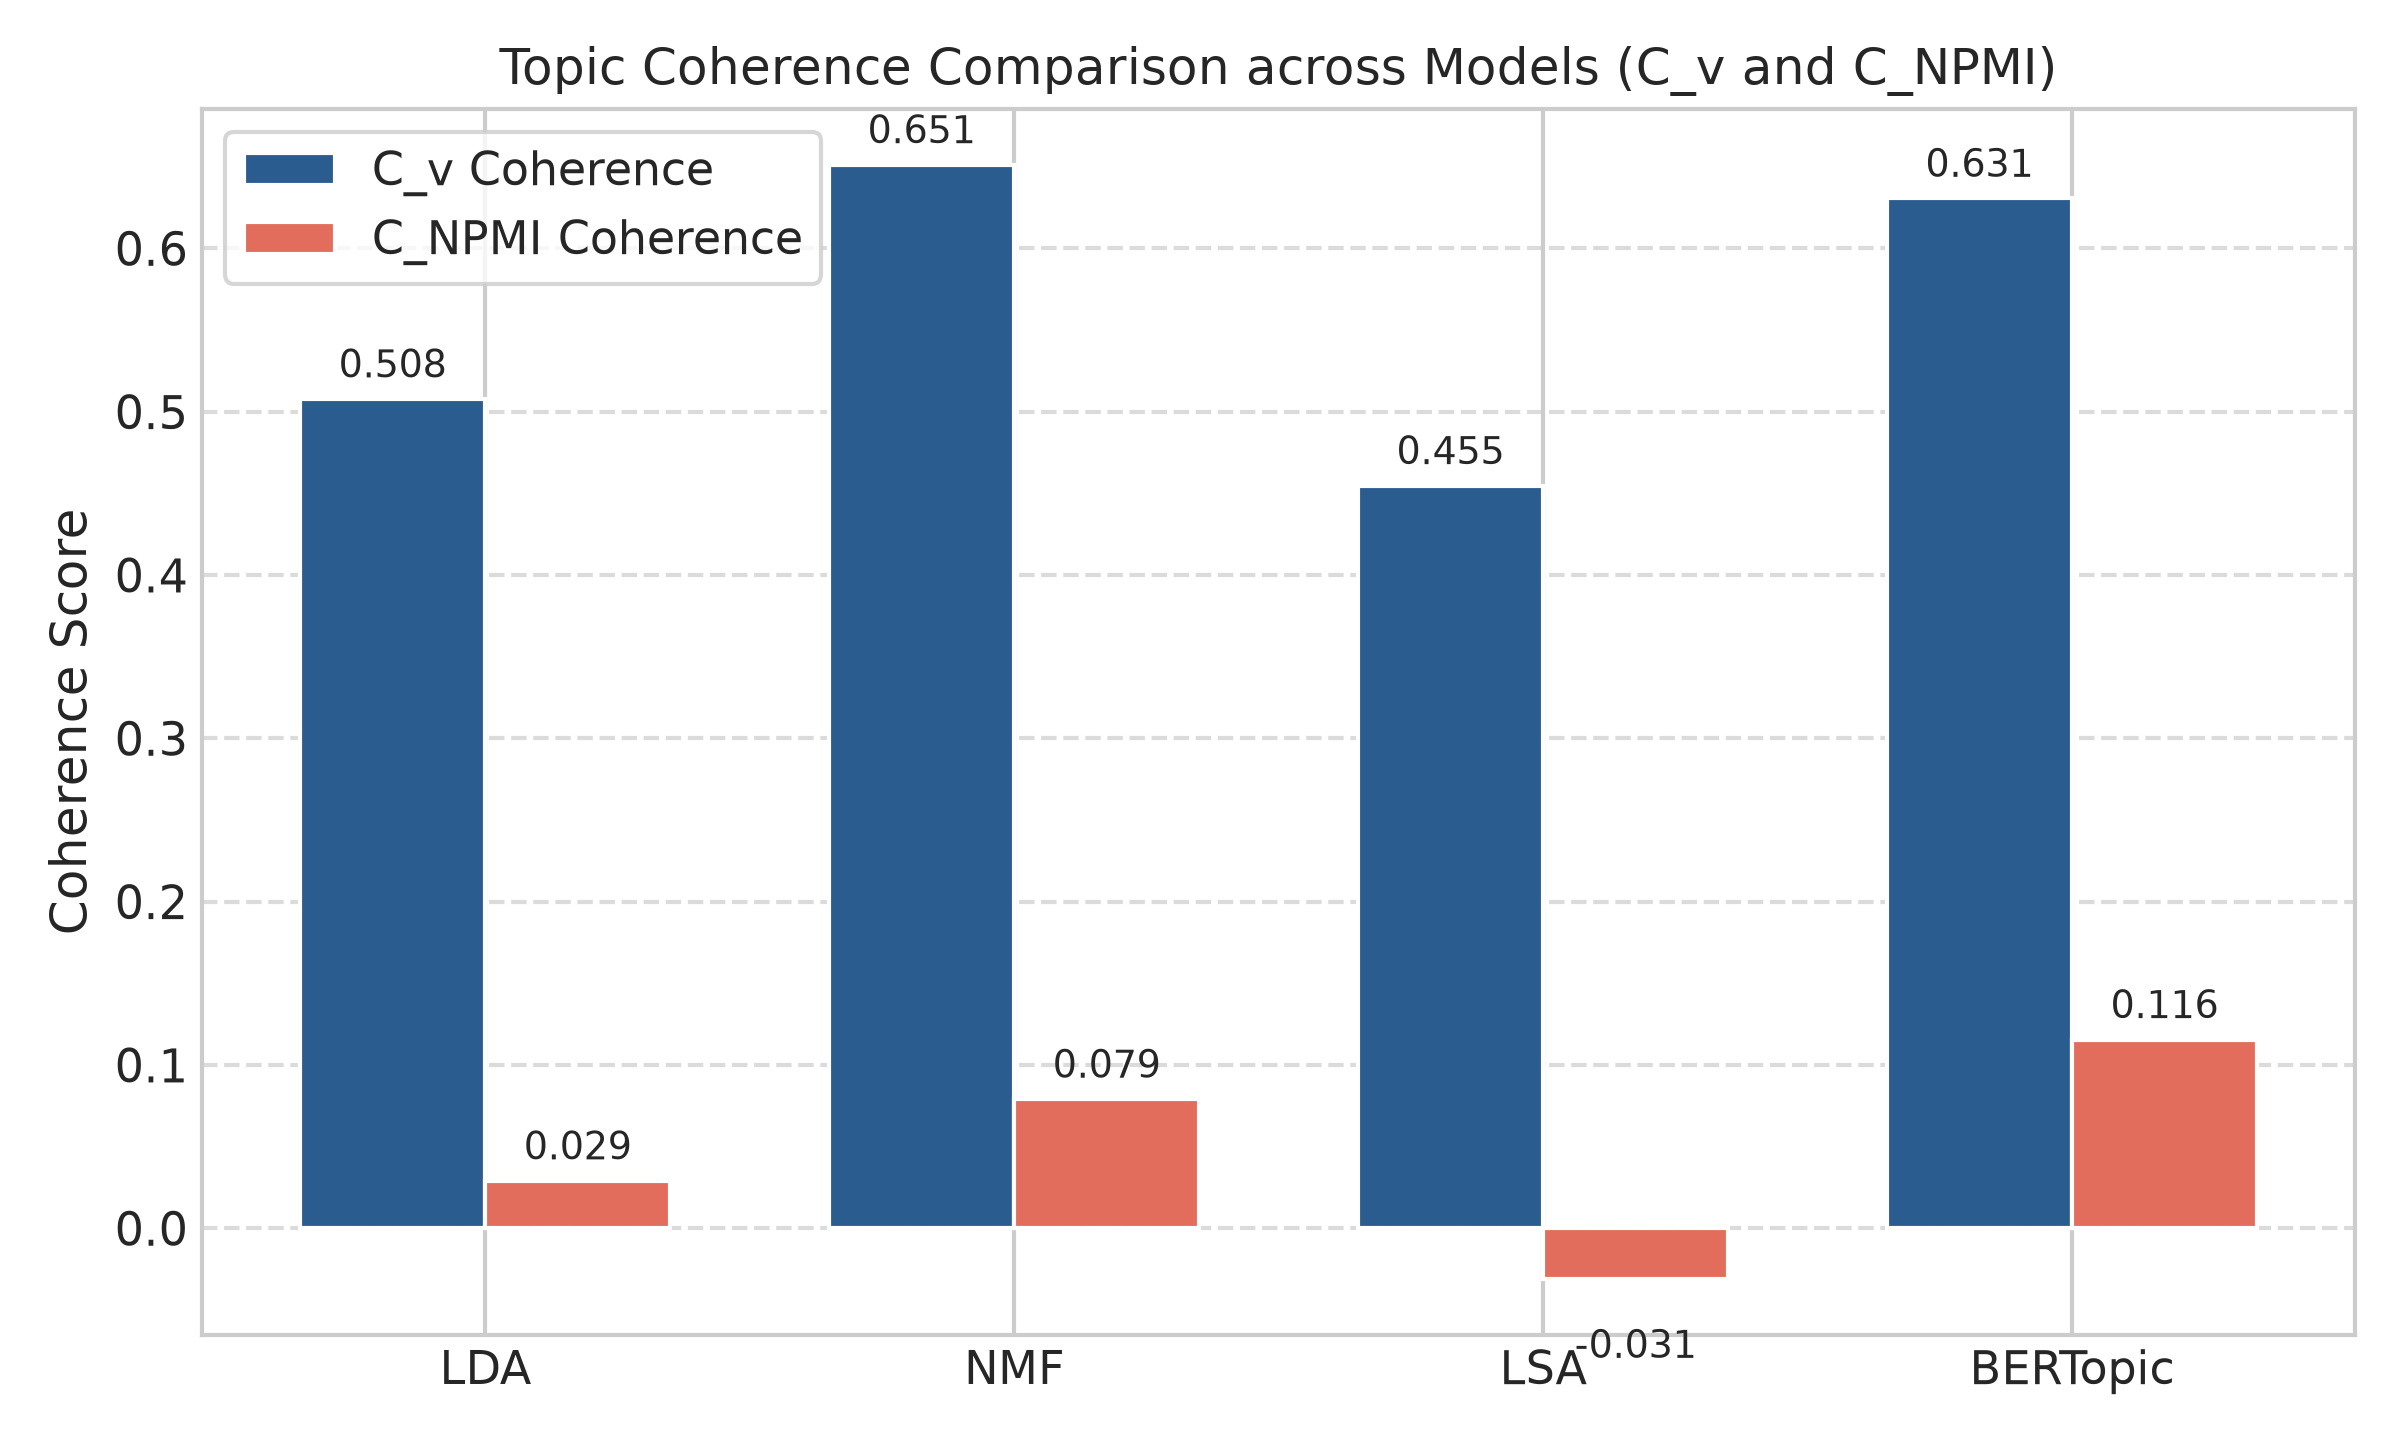

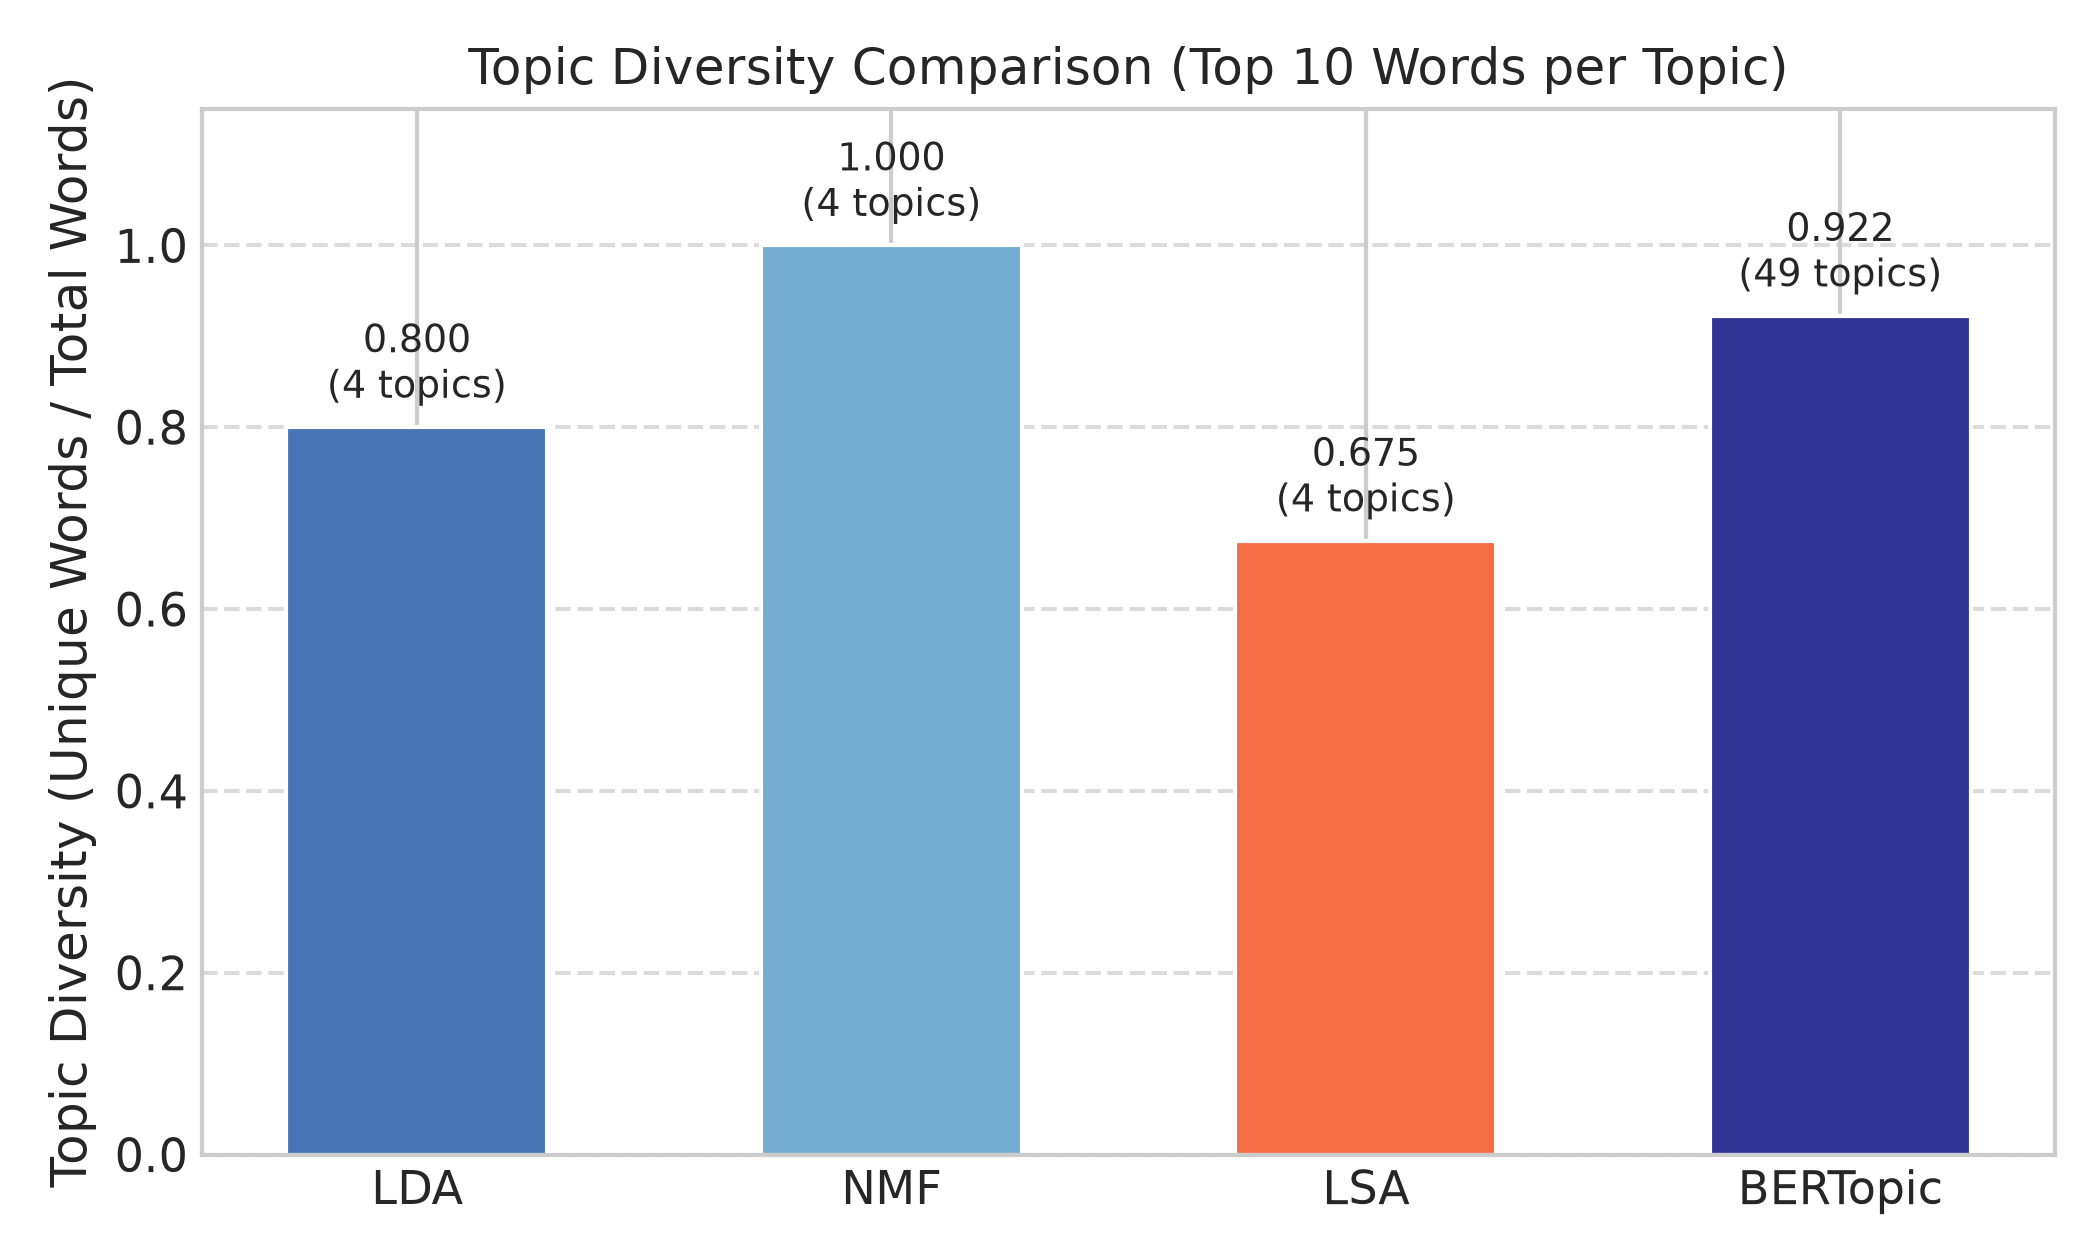

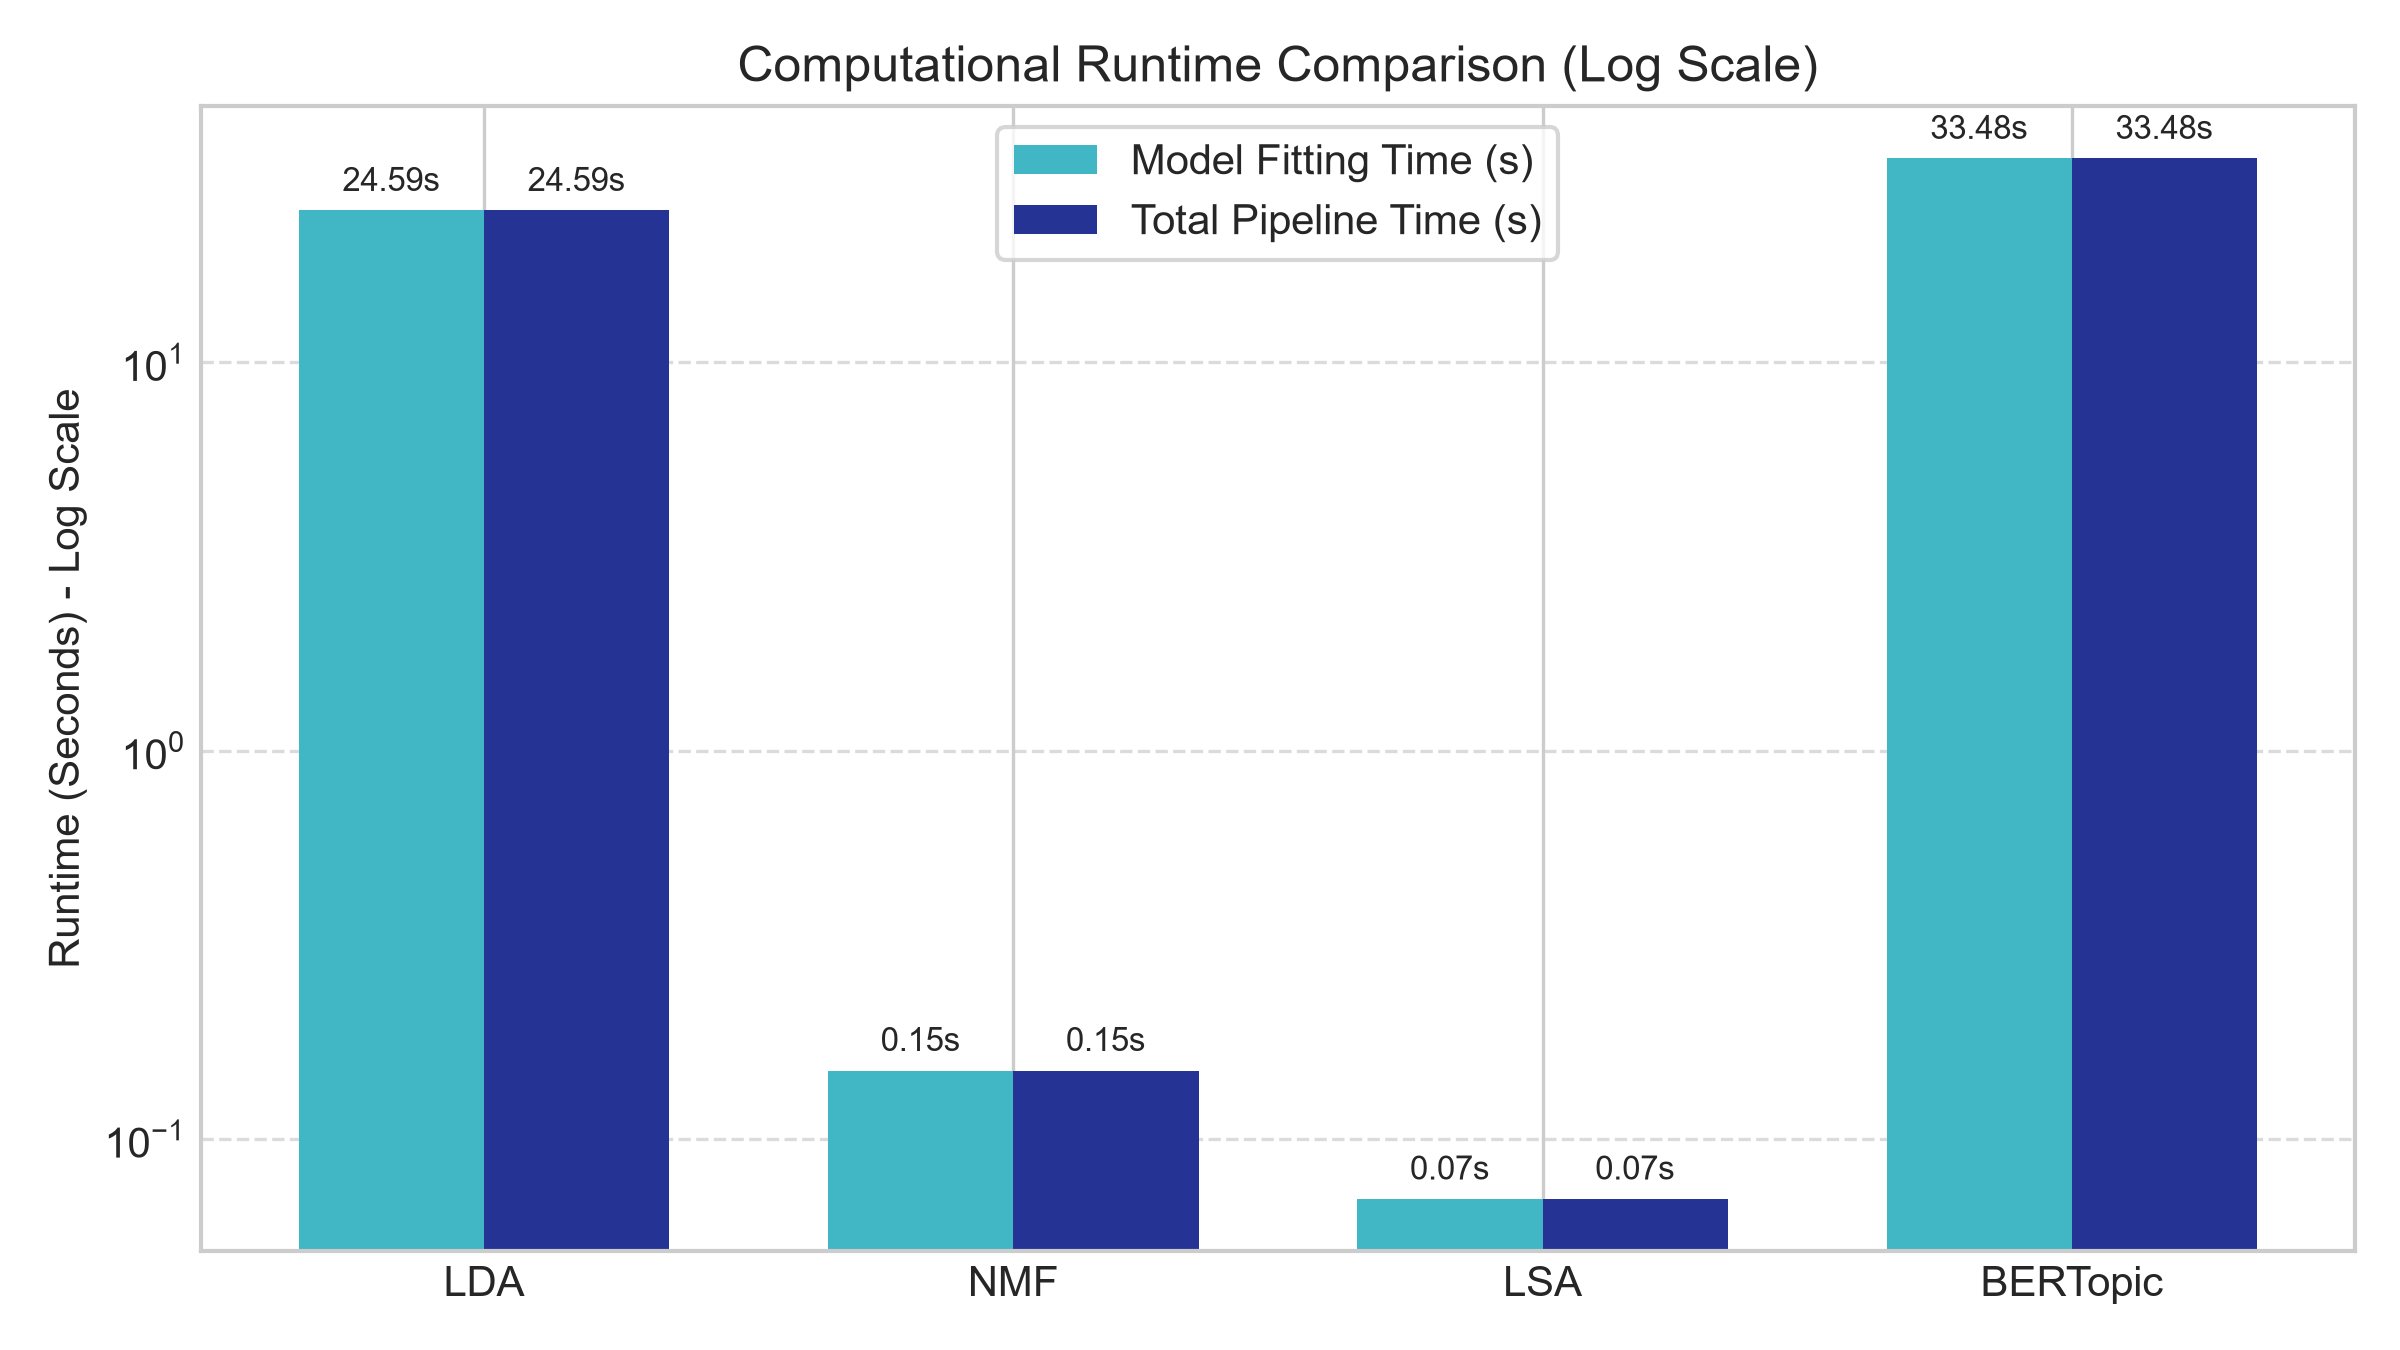

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

# 1. Topic Coherence Comparison
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(df_coherence))
width = 0.35
rects1 = ax.bar(x - width/2, df_coherence['C_v'], width, label='C_v Coherence', color='#2b5c8f')
rects2 = ax.bar(x + width/2, df_coherence['C_NPMI'], width, label='C_NPMI Coherence', color='#e26d5c')
ax.set_ylabel('Coherence Score')
ax.set_title('Topic Coherence Comparison across Models (C_v and C_NPMI)')
ax.set_xticks(x)
ax.set_xticklabels(df_coherence['Model'])
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.7)
for r in rects1:
    h = r.get_height()
    ax.annotate(f'{h:.3f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9)
for r in rects2:
    h = r.get_height()
    offset = 3 if h >= 0 else -12
    ax.annotate(f'{h:.3f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, offset),
                textcoords="offset points", ha='center', va='bottom' if h>=0 else 'top', fontsize=9)
plt.tight_layout()
fig.savefig(results_dir / "topic_coherence_comparison.png", dpi=300)
plt.show()

# 2. Topic Diversity Comparison
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(df_diversity['Model'], df_diversity['Topic_Diversity'], color=['#4575b4', '#74add1', '#f46d43', '#313695'], width=0.55)
ax.set_ylabel('Topic Diversity (Unique Words / Total Words)')
ax.set_ylim(0, 1.15)
ax.set_title('Topic Diversity Comparison (Top 10 Words per Topic)')
ax.grid(axis='y', linestyle='--', alpha=0.7)
for bar, (_, row) in zip(bars, df_diversity.iterrows()):
    h = bar.get_height()
    t_n = row['Topics_Evaluated']
    ax.annotate(f'{h:.3f}\n({t_n} topics)', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
fig.savefig(results_dir / "topic_diversity_comparison.png", dpi=300)
plt.show()

# 3. Runtime Comparison
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(df_comparison))
width = 0.35
r1 = ax.bar(x - width/2, df_comparison['Runtime_Fitting_s'], width, label='Model Fitting Time (s)', color='#41b6c4')
r2 = ax.bar(x + width/2, df_comparison['Runtime_Total_s'], width, label='Total Pipeline Time (s)', color='#253494')
ax.set_ylabel('Runtime (Seconds) - Log Scale')
ax.set_yscale('log')
ax.set_title('Computational Runtime Comparison (Log Scale)')
ax.set_xticks(x)
ax.set_xticklabels(df_comparison['Model'])
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.7)
for r, val in zip(r1, df_comparison['Runtime_Fitting_s']):
    ax.annotate(f'{val:.2f}s', xy=(r.get_x() + r.get_width()/2, val), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=8)
for r, val in zip(r2, df_comparison['Runtime_Total_s']):
    ax.annotate(f'{val:.2f}s', xy=(r.get_x() + r.get_width()/2, val), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=8)
plt.tight_layout()
fig.savefig(results_dir / "topic_runtime_comparison.png", dpi=300)
plt.show()

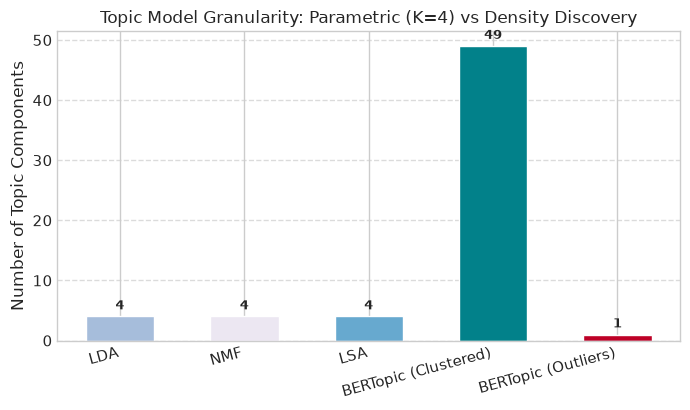

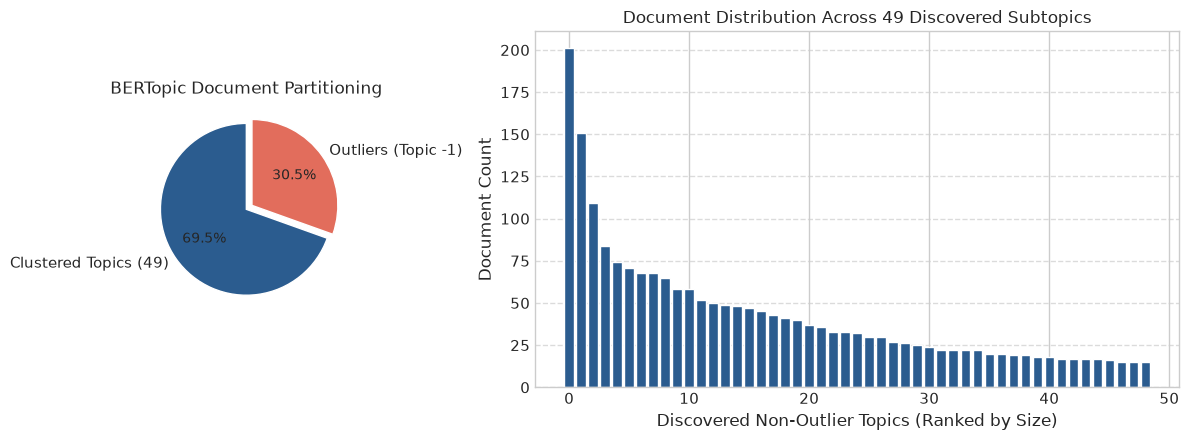

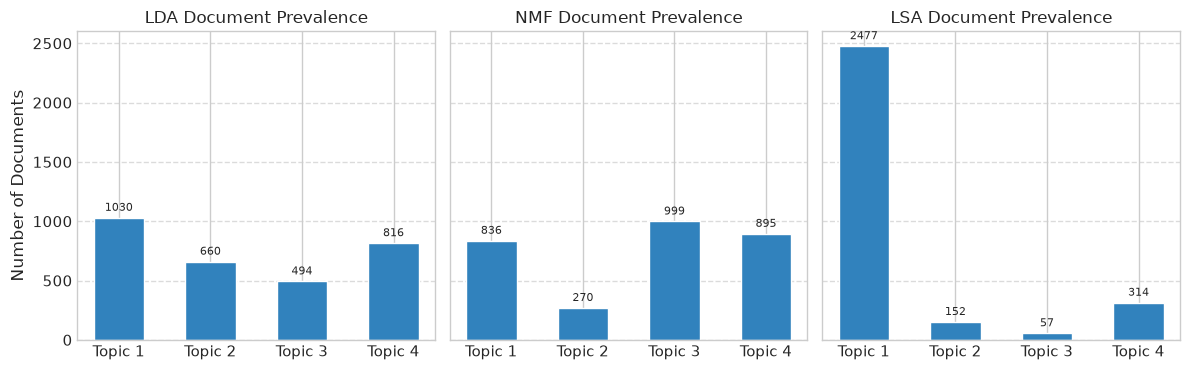

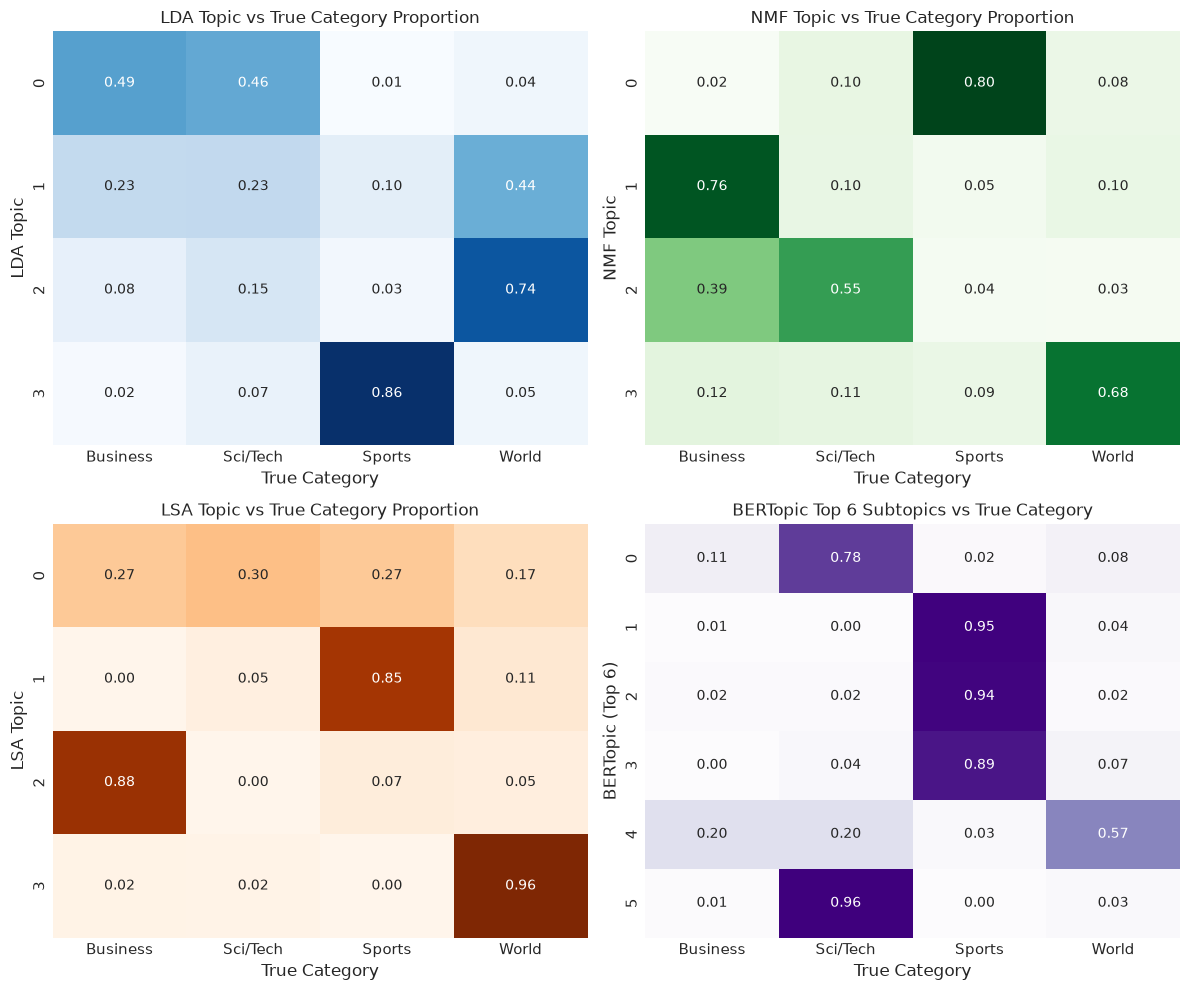

In [16]:
# 4. Discovered Topic Counts Comparison
fig, ax = plt.subplots(figsize=(7, 4.2))
models_tc = ['LDA', 'NMF', 'LSA', 'BERTopic (Clustered)', 'BERTopic (Outliers)']
counts = [4, 4, 4, total_topics_discovered, 1]
col_tc = ['#a6bddb', '#ece7f2', '#67a9cf', '#02818a', '#bd0026']
bars = ax.bar(models_tc, counts, color=col_tc, width=0.55)
ax.set_ylabel('Number of Topic Components')
ax.set_title('Topic Model Granularity: Parametric (K=4) vs Density Discovery')
ax.grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f'{h}', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
fig.savefig(results_dir / "topic_counts_comparison.png", dpi=300)
plt.show()

# 5. BERTopic Topic Size Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 3]})
ax1.pie([len(documents) - outlier_count, outlier_count], labels=['Clustered Topics (49)', 'Outliers (Topic -1)'],
        autopct='%1.1f%%', colors=['#2b5c8f', '#e26d5c'], startangle=90, explode=(0, 0.08))
ax1.set_title('BERTopic Document Partitioning')

clean_topics_info = topic_info[topic_info['Topic'] != -1].sort_values('Count', ascending=False)
ax2.bar(range(len(clean_topics_info)), clean_topics_info['Count'], color='#2b5c8f', width=0.8)
ax2.set_xlabel('Discovered Non-Outlier Topics (Ranked by Size)')
ax2.set_ylabel('Document Count')
ax2.set_title('Document Distribution Across 49 Discovered Subtopics')
ax2.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
fig.savefig(results_dir / "bertopic_size_distribution.png", dpi=300)
plt.show()

# 6. Topic Prevalence Comparison (Classical Models)
classical_counts_dict = {}
for m_name, d_top in classical_doc_topics.items():
    dom = np.argmax(d_top, axis=1)
    classical_counts_dict[m_name] = np.bincount(dom, minlength=4)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for i, (m_name, c_arr) in enumerate(classical_counts_dict.items()):
    ax = axes[i]
    ax.bar([f'Topic {k+1}' for k in range(4)], c_arr, color='#3182bd', width=0.55)
    ax.set_title(f'{m_name} Document Prevalence')
    ax.set_ylabel('Number of Documents' if i == 0 else '')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    for idx, v in enumerate(c_arr):
        ax.annotate(str(v), xy=(idx, v), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
plt.tight_layout()
fig.savefig(results_dir / "topic_prevalence_comparison.png", dpi=300)
plt.show()

# 7. Topic-Category Contingency Heatmaps
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ct_lda = pd.crosstab(pd.Series(lda_dominant, name='LDA Topic'), pd.Series(true_categories, name='True Category'), normalize='index')
sns.heatmap(ct_lda, annot=True, fmt='.2f', cmap='Blues', ax=axes[0, 0], cbar=False)
axes[0, 0].set_title('LDA Topic vs True Category Proportion')

ct_nmf = pd.crosstab(pd.Series(nmf_dominant, name='NMF Topic'), pd.Series(true_categories, name='True Category'), normalize='index')
sns.heatmap(ct_nmf, annot=True, fmt='.2f', cmap='Greens', ax=axes[0, 1], cbar=False)
axes[0, 1].set_title('NMF Topic vs True Category Proportion')

ct_lsa = pd.crosstab(pd.Series(lsa_dominant, name='LSA Topic'), pd.Series(true_categories, name='True Category'), normalize='index')
sns.heatmap(ct_lsa, annot=True, fmt='.2f', cmap='Oranges', ax=axes[1, 0], cbar=False)
axes[1, 0].set_title('LSA Topic vs True Category Proportion')

top_6_ids = clean_topics_info.head(6)['Topic'].tolist()
bert_mask = np.isin(bertopic_arr, top_6_ids)
ct_bert = pd.crosstab(pd.Series(bertopic_arr[bert_mask], name='BERTopic (Top 6)'), pd.Series(true_categories[bert_mask], name='True Category'), normalize='index')
sns.heatmap(ct_bert, annot=True, fmt='.2f', cmap='Purples', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('BERTopic Top 6 Subtopics vs True Category')

plt.tight_layout()
fig.savefig(results_dir / "topic_category_contingency.png", dpi=300)
plt.show()

## Stage F: Interpretation and Limitations

### 1. Algorithmic Paradigms & Mathematical Formulations
- **Latent Dirichlet Allocation (LDA):** As a generative Bayesian model, LDA treats each document as a Dirichlet-distributed mixture over $K=4$ topics, and each topic as a Dirichlet-distributed distribution over words. While mathematically principled, LDA struggles with short news texts where word co-occurrence matrices are sparse. Furthermore, its topics exhibit vocabulary overlap with high-frequency corpus words (`said`, `new`, `ap`), yielding moderate coherence ($C_v = 0.5078, C_{\text{NPMI}} = +0.0290$) and a fitting runtime of 24.59s.
- **Non-negative Matrix Factorization (NMF):** By constraining the factorization $V \approx W H$ to strictly non-negative values, NMF produces an additive, parts-based semantic representation. Applied to TF-IDF weights, NMF achieved the highest topic coherence among classical models ($C_v = 0.6512$) and perfect topic diversity ($1.0000$, with zero keyword repetition across topics). Its training was near-instantaneous ($0.15$s), clearly delineating the four AG News domains into Sports (Topic 1), Oil/Markets (Topic 2), Software/Tech (Topic 3), and World Conflict (Topic 4).
- **Latent Semantic Analysis (LSA / TruncatedSVD):** LSA computes an unconstrained low-rank approximation via Singular Value Decomposition. Because singular vectors enforce orthogonality rather than non-negativity, components allow negative weights and capture global corpus variance rather than localized themes. The first component absorbed corpus-wide frequencies (2,477 documents assigned to Topic 1), resulting in the lowest coherence ($C_v = 0.4547, C_{\text{NPMI}} = -0.0310$) and lowest diversity ($0.6750$).
- **BERTopic (Neural Density Architecture):** By replacing bag-of-words representations with dense SentenceTransformer embeddings (`all-MiniLM-L6-v2`), BERTopic preserves context, polysemy, and phrase-level semantics. Dimensionality reduction via UMAP and density clustering via HDBSCAN enable non-parametric subtopic discovery, yielding the highest $C_{\text{NPMI}}$ coherence ($+0.1155$) and strong $C_v$ ($0.6306$) across 49 distinct topics.

### 2. Topic Granularity: Macro-Categories ($K=4$) vs. Micro-Themes ($K=49$)
- Classical models were parameterized with fixed $K=4$ matching the broad editorial categories of AG News. Consequently, broad topics like "Sports" or "World" aggregate diverse events into single mixtures.
- In contrast, BERTopic dynamically discovered 49 granular subtopics. For example, rather than a broad "Sports" category, BERTopic isolated *Red Sox/Yankees Baseball* (Topic 1), *European Champions League Football* (Topic 2), and *Athens Summer Olympics* (Topic 3). Similarly, "Sci/Tech" was decomposed into *NASA & Space Exploration* (Topic 0), *Windows Security Updates* (Topic 5), and *Mobile Java Standards* (Topic 7).

### 3. Topic Coherence vs. Keyword Diversity Trade-Off
- NMF achieved perfect diversity ($1.0000$) across 40 terms by exploiting TF-IDF term specificity, while LDA achieved diversity of $0.8000$ (32 unique terms across 40 words) and LSA scored $0.6750$.
- BERTopic maintained an outstanding diversity of $0.9224$ across **490 total keywords** (452 unique terms). This demonstrates that expanding the topic count by an order of magnitude did not degrade keyword distinctiveness, because dense embeddings effectively separate specialized vocabularies.

### 4. Computational Complexity and Scalability
- Linear algebra approaches demonstrated extreme computational efficiency: LSA required only **0.07s** and NMF required **0.15s**.
- LDA required **24.59s** due to iterative variational expectation-maximization over document distributions.
- BERTopic requires distinguishing between cached and cold-start execution:
  * **Cached-Embedding Fitting:** Fitting UMAP, HDBSCAN, and c-TF-IDF using precomputed embeddings required **33.48s**.
  * **Cold-Start End-to-End Pipeline:** Generating the dense 384-dimensional representations via `all-MiniLM-L6-v2` across 3,000 documents required **103.69s** on CPU, resulting in a total cold-start runtime of **137.17s** (103.69s + 33.48s).
  * While transformer inference introduces significant upfront overhead, embeddings can be precomputed and reused across downstream clustering and topic exploration tasks.

### 5. Outlier Analysis: Noise and Boundary Documents in HDBSCAN
- HDBSCAN designated **914 documents (30.47%)** as outlier Topic `-1`. In density clustering, an outlier does not necessarily represent nonsensical text; rather, it identifies documents residing in low-density transition regions between dense topic manifolds (e.g., articles combining business mergers with software technology, or general political commentary).
- Isolating these ambiguous documents purifies the remaining 49 clusters, but fundamentally alters the evaluation scope. Evaluating BERTopic on the clean subset (2,086 documents) yields an NMI of **0.4041**, but this represents an upper-bound cluster alignment on dense cores. On the full sample of 3,000 documents (treating Topic `-1` as a 50th topic), BERTopic's NMI is **0.3151**.

### 6. Alignment Against Ground-Truth AG News Categories (NMI)
- On the full 3,000-document sample, **NMF achieved the highest category alignment** ($	ext{NMI} = 0.3858$), closely followed by **LDA** ($0.3822$). Both models partitioned the full corpus into four broad clusters that map directly onto the four editorial desks.
- **LSA exhibited the lowest category alignment** ($	ext{NMI} = 0.2022$), as its dominant first component pooled over 82% of the documents into a single cluster.
- **BERTopic's clean-cluster NMI** ($0.4041$) reflects strong domain concordance within dense cores, but must be interpreted cautiously because 30.47% of difficult, overlapping documents were removed prior to scoring.

### 7. Multi-Criteria Model Synthesis
No single model is universally superior; selection depends on project requirements:
- **NMF** is optimal for macro-level topic discovery ($K=4$), offering the best combination of coherence ($C_v = 0.6512$), perfect diversity ($1.0000$), highest full-sample NMI ($0.3858$), and near-instant runtime ($0.15$s).
- **BERTopic** is optimal for fine-grained semantic exploration (discovering 49 cohesive subtopics) and achieves the highest mutual information ($C_{\text{NPMI}} = +0.1155$), but requires substantial compute ($137.17$s cold start) and unassigns 30.5% of articles.
- **LDA** provides a soft probabilistic framework but is slower ($24.59$s) and exhibits vocabulary redundancy on short texts (diversity: $0.8000$).
- **LSA** serves as a fast baseline ($0.07$s) but suffers from orthogonality constraints that blend disparate domains.

### 8. Methodological Limitations
1. **Sample Size:** Evaluation was conducted on a reproducible random sample of 3,000 documents to ensure computational feasibility within notebook runtime constraints.
2. **Hyperparameter Sensitivity:** UMAP's `n_neighbors` (15) and HDBSCAN's `min_cluster_size` (15) directly dictate the granularity and outlier rate; adjusting these parameters will alter the number of discovered topics.
3. **Short-Text Sparsity:** AG News texts are concise news snippets; while contextual transformer embeddings compensate for text brevity, bag-of-words classical models remain susceptible to sparse co-occurrences.
4. **Evaluation Dictionary vs. Multi-Word Keywords:** Because the reference corpus uses unigram tokenization, multi-word bigram keywords extracted by BERTopic's c-TF-IDF (71 bigrams out of 490 words) are omitted by Gensim from sliding-window PMI coherence calculations. Coherence for BERTopic was therefore evaluated over an average of 8.55 in-vocabulary unigram terms per topic (ranging from 6 to 10 terms) rather than a strict 10-word window. While this provides a standardized unigram reference frame across models, it means that joint co-occurrences of multi-word phrases are not directly captured.